In [1]:
from langgraph.graph import StateGraph, END
from IPython.display import Image

In [2]:
# Agent Functions
def user_agent(state):
    print("UserAgent: Placing the order...")
    state["order_placed"] = True
    return state

def quantity_agent(state):
    if not state.get("order_placed"):
        raise ValueError("Order not placed, try after some time.")
    print("QuantityAgent: Checking available stock...")
    state["quantity_available"] = True  # Set False to simulate stock out
    return state

def payment_agent(state):
    if not state.get("quantity_available"):
        raise ValueError("Insufficient quantity, can't proceed to payment.")
    print("PaymentAgent: Processing payment...")
    state["payment_done"] = True
    return state


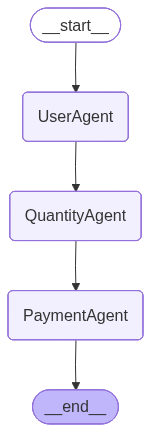

In [3]:
subgraph = StateGraph(dict)

# Add agents
subgraph.add_node("UserAgent", user_agent)
subgraph.add_node("QuantityAgent", quantity_agent)
subgraph.add_node("PaymentAgent", payment_agent)

# Define flow
subgraph.set_entry_point("UserAgent")
subgraph.add_edge("UserAgent", "QuantityAgent")
subgraph.add_edge("QuantityAgent", "PaymentAgent")

# Final node
subgraph.set_finish_point("PaymentAgent")

compiled_subgraph = subgraph.compile()

png_bytes = compiled_subgraph.get_graph().draw_mermaid_png()
Image(png_bytes)

In [4]:
parent_graph = StateGraph(dict)

# Add the compiled subgraph
parent_graph.add_node("EcommerceFlow", compiled_subgraph)
parent_graph.set_entry_point("EcommerceFlow")
parent_graph.set_finish_point("EcommerceFlow")

compiled_parent_graph = parent_graph.compile()


# Initial state
state = {
    "order_placed": False,
    "quantity_available": False,
    "payment_done": False
}

# Execute
result = compiled_parent_graph.invoke(state)
print("Final State:", result)

UserAgent: Placing the order...
QuantityAgent: Checking available stock...
PaymentAgent: Processing payment...
Final State: {'order_placed': True, 'quantity_available': True, 'payment_done': True}


In [5]:
import os, getpass

def _set_env(var: str):
    if not os.environ.get(var):
        os.environ[var] = getpass.getpass(f"{var}: ")

_set_env("OPENAI_API_KEY")

In [7]:
from typing import TypedDict, Annotated
import operator
from langchain_openai import ChatOpenAI

In [8]:
# Define state structure for the subgraph
class MultiAgentState(TypedDict):
    messages: Annotated[list, operator.add]
    task: str
    research_done: bool
    analysis_done: bool
    final_summary: str


In [9]:
# Initialize LLM
llm = ChatOpenAI(model="gpt-4o", temperature=0.7)

# Agent 1: Research Agent
def research_agent_llm(state: MultiAgentState) -> MultiAgentState:
    print("ResearchAgent: Gathering information...")
    prompt = f"Research the following topic and provide key insights: {state['task']}"
    response = llm.invoke(prompt)
    state["messages"].append({"agent": "research", "content": response.content})
    state["research_done"] = True
    return state

# Agent 2: Analysis Agent
def analysis_agent_llm(state: MultiAgentState) -> MultiAgentState:
    print("AnalysisAgent: Analyzing data...")
    research_content = state["messages"][-1]["content"]
    prompt = f"Analyze the following research findings and provide deeper insights: {research_content}"
    response = llm.invoke(prompt)
    state["messages"].append({"agent": "analysis", "content": response.content})
    state["analysis_done"] = True
    return state

# Agent 3: Summary Agent
def summary_agent_llm(state: MultiAgentState) -> MultiAgentState:
    print("SummaryAgent: Creating final summary...")
    all_content = "\n".join([msg["content"] for msg in state["messages"]])
    prompt = f"Create a concise summary of the following research and analysis: {all_content}"
    response = llm.invoke(prompt)
    state["messages"].append({"agent": "summary", "content": response.content})
    state["final_summary"] = response.content
    return state



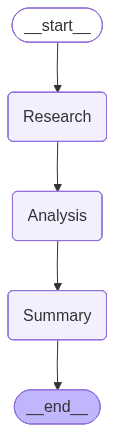

In [10]:
# Build the multi-agent subgraph
multi_agent_subgraph = StateGraph(MultiAgentState)

# Add agents
multi_agent_subgraph.add_node("Research", research_agent_llm)
multi_agent_subgraph.add_node("Analysis", analysis_agent_llm)
multi_agent_subgraph.add_node("Summary", summary_agent_llm)

# Define flow
multi_agent_subgraph.set_entry_point("Research")
multi_agent_subgraph.add_edge("Research", "Analysis")
multi_agent_subgraph.add_edge("Analysis", "Summary")
multi_agent_subgraph.set_finish_point("Summary")

# Compile the subgraph
compiled_multi_agent = multi_agent_subgraph.compile()

png_bytes = compiled_multi_agent.get_graph().draw_mermaid_png()
Image(png_bytes)



In [11]:
# Test the subgraph
test_state = {
    "messages": [],
    "task": "Explain the benefits of multi-agent systems in AI",
    "research_done": False,
    "analysis_done": False,
    "final_summary": ""
}

# Execute
result_multi_agent = compiled_multi_agent.invoke(test_state)
print("\n=== Final Summary ===")
print(result_multi_agent["final_summary"])

ResearchAgent: Gathering information...
AnalysisAgent: Analyzing data...
SummaryAgent: Creating final summary...

=== Final Summary ===
Multi-agent systems (MAS) in AI, which involve multiple interacting autonomous agents, offer substantial advantages over single-agent systems, particularly in handling complex and dynamic problems. Key benefits include scalability, allowing MAS to manage expansive tasks by distributing workloads; robustness, which enhances system reliability through fault tolerance; and parallel processing, which accelerates solutions by enabling simultaneous task execution. These systems are adaptable, allowing for easy reconfiguration in response to environmental changes, and they support specialization, enabling agents to develop domain-specific expertise for more efficient problem-solving.

MAS are also adept at modeling cooperation and collaboration, making them ideal for applications in traffic management, resource allocation, and collaborative robotics. They exc

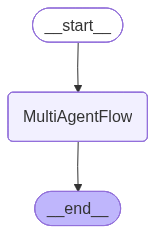

In [13]:
# Create parent graph with the multi-agent subgraph
parent_multi_agent_graph = StateGraph(MultiAgentState)

# Add the compiled multi-agent subgraph as a node
parent_multi_agent_graph.add_node("MultiAgentFlow", compiled_multi_agent)
parent_multi_agent_graph.set_entry_point("MultiAgentFlow")
parent_multi_agent_graph.set_finish_point("MultiAgentFlow")

# Compile the parent graph
compiled_parent_multi_agent = parent_multi_agent_graph.compile()

# Visualize the parent graph
png_bytes = compiled_parent_multi_agent.get_graph().draw_mermaid_png()
Image(png_bytes)

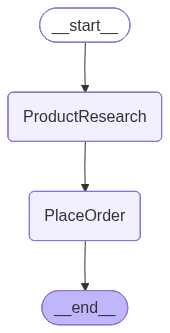

In [15]:
# Create a unified parent graph that contains both subgraphs
from typing import Any

# Define a unified state that can handle both workflows
class UnifiedState(TypedDict):
    # E-commerce fields
    order_placed: bool
    quantity_available: bool
    payment_done: bool
    # Multi-agent fields
    messages: Annotated[list, operator.add]
    task: str
    research_done: bool
    analysis_done: bool
    final_summary: str
    # Product information
    product_name: str
    product_recommendation: str

# Create the unified parent graph
unified_parent_graph = StateGraph(UnifiedState)

# Add both compiled subgraphs as nodes
unified_parent_graph.add_node("ProductResearch", compiled_multi_agent)
unified_parent_graph.add_node("PlaceOrder", compiled_subgraph)

# Define the workflow: Research first, then place order
unified_parent_graph.set_entry_point("ProductResearch")

# Add direct edge from ProductResearch to PlaceOrder
unified_parent_graph.add_edge("ProductResearch", "PlaceOrder")

# PlaceOrder goes to END
unified_parent_graph.add_edge("PlaceOrder", END)

# Compile the unified parent graph
compiled_unified_parent = unified_parent_graph.compile()

# Visualize the unified parent graph
png_bytes = compiled_unified_parent.get_graph().draw_mermaid_png()
Image(png_bytes)


In [16]:
# Test the unified parent graph: Research product then place order

# Product to research and order
product_to_buy = "wireless noise-cancelling headphones"

# Initialize the unified state
unified_state = {
    # E-commerce fields
    "order_placed": False,
    "quantity_available": False,
    "payment_done": False,
    # Multi-agent fields
    "messages": [],
    "task": f"Research {product_to_buy} and provide key features, benefits, and recommendations for purchase",
    "research_done": False,
    "analysis_done": False,
    "final_summary": "",
    # Product information
    "product_name": product_to_buy,
    "product_recommendation": ""
}

# Execute the unified workflow
print("=== Executing Product Research → Order Placement Workflow ===\n")
print(f"Product to research: {product_to_buy}\n")

result_unified = compiled_unified_parent.invoke(unified_state)

# Display results
print("\n" + "="*60)
print("=== PRODUCT RESEARCH RESULTS ===")
print("="*60)
if result_unified.get('final_summary'):
    print(result_unified['final_summary'])

print("\n" + "="*60)
print("=== ORDER PLACEMENT RESULTS ===")
print("="*60)
print(f"Product: {result_unified['product_name']}")
print(f"Order Placed: {result_unified['order_placed']}")
print(f"Quantity Available: {result_unified['quantity_available']}")
print(f"Payment Done: {result_unified['payment_done']}")
print("\n✓ Order successfully completed!" if result_unified['payment_done'] else "\n✗ Order failed")


=== Executing Product Research → Order Placement Workflow ===

Product to research: wireless noise-cancelling headphones

ResearchAgent: Gathering information...
AnalysisAgent: Analyzing data...
AnalysisAgent: Analyzing data...
SummaryAgent: Creating final summary...
SummaryAgent: Creating final summary...
UserAgent: Placing the order...
QuantityAgent: Checking available stock...
PaymentAgent: Processing payment...

=== PRODUCT RESEARCH RESULTS ===
The research on wireless noise-cancelling headphones highlights key features, benefits, and recommended models to guide purchasing decisions based on individual needs and preferences. 

### Key Features:
1. **Active Noise Cancellation (ANC):** Utilizes microphones and speakers to reduce ambient noise, with effectiveness varying by model and environment.
2. **Sound Quality:** Offers clear, balanced audio, often with customizable sound profiles via apps.
3. **Battery Life:** Ranges from 15 to 40 hours, with many models featuring quick charging